READ ME:
- ho letto il codice che avevi scritto per la maschera, il problema che era sorto è che nel provare trials > 10**4 era lento dato che generava tutte le possibili maschere e le provava a trovare casualmente, perciò ho riscritto il codice
- vi commento le funzioni, se manca qualche grafico o cosa fatemi sapere

In [159]:
import random
import math
import matplotlib.pyplot as plt
import scipy.special as sp # used to evaluate the binomial operator for the wirtap channel prob.
import numpy as np

# Plot function

In [160]:
def scatter_plot_from_dict(data_dict, title ="marginal distribution of z", xlabel = "message", ylabel = "prob"):
  """Plots a scatter plot from a dictionary of floats.

  Args:
    data_dict: A dictionary where keys are x-values and values are y-values.
  """
  x_values = list(data_dict.keys())
  y_values = list(data_dict.values())

  plt.scatter(x_values, y_values)
  plt.xlabel(xlabel)
  plt.ylabel(ylabel)
  plt.title(title)
  plt.show()

## Probabilities function

In [161]:
def conditional_pmd(messages):
  """given a map of pair (u,z)->(#sample) it returns a map (u,z) -> p(z|u)
  """
  conditional_pmd = defaultdict(lambda: defaultdict(float))
  for u in range(len(messages)):
    total_samples = sum(messages[u].values())
    for z in messages[u]:
      conditional_pmd[u][z] += messages[u][z] / total_samples
  return conditional_pmd

def marginal_pmd(joint_pmd):
  """given a map of pair (u,z)->(p(u,z)) it returns a map (z) -> p(z)
  """
  marginal_pmd = defaultdict(float)
  for u in range(len(joint_pmd)):
    for z in joint_pmd[u]:
      marginal_pmd[z] += joint_pmd[u][z]
  return marginal_pmd

#should be close to zero
#assume that the u present in joint_pmd are the same as the one in marginal_pmd_u
def mutual_information(joint_pmd, marginal_pmd_z, marginal_pmd_u):
  """given the marginal pmd of u a map (u) -> p(u) and z a map (z) -> p(z) and
     the joint pmd of u and z (a map (u,z) -> p(u|z)) it returns the mutual information
     between u and z
  """
  I = 0
  for u in joint_pmd:
    for z in joint_pmd[u]:
      I += joint_pmd[u][z] * math.log2(joint_pmd[u][z] / (marginal_pmd_z[z] * marginal_pmd_u[u]))
  return I

def channel_prob(conditional_pmd_dict):
  joint_pmd = defaultdict(lambda: defaultdict(float))
  for u in conditional_pmd_dict:
      for z in conditional_pmd_dict[u]:
          joint_pmd[u][z] = conditional_pmd_dict[u][z] * (1/8)
  marginal_pmd_z = marginal_pmd(joint_pmd)
  marginal_pmd_u = defaultdict(float)
  for u in range(8):
    marginal_pmd_u[u] = 1/8
  return joint_pmd, marginal_pmd_z, marginal_pmd_u

used to get the joint pmd and total variation distance form a dictionari of uzu*

In [162]:
def joint_pmd_uzu(messages):
  """given a map of (u,z,u')->(#sample) it returns a map (u,z,u') -> p(z,u',u)
     for simplicty it consider that the probability of each u is Uniform and it's equal
     to 1/8
  """
  conditional_pmd = defaultdict(lambda: defaultdict(lambda: defaultdict(float)))
  for u in range(len(messages)):
    total_samples = sum(sum(inner_dict.values()) for inner_dict in messages[u].values())
    for z in messages[u]:
      for u1 in messages[u][z]:
        conditional_pmd[u][z][u1] += messages[u][z][u1] / total_samples
        conditional_pmd[u][z][u1] *= 1/8
  return conditional_pmd


def total_var_distance(dictionary_ideal, dictionary_real):
  """given two map of (u,z,u')->(#sample), one sampled from the ideal mechanism
     and one sampled from the real mechanism it returns the total variation distance
     between them
  """
  ideal_probabilities = joint_pmd_uzu(dictionary_ideal)
  real_probabilities = joint_pmd_uzu(dictionary_real)
  total_distance = 0
  #Complete by calculating the toatal variation distance beten ideal and real
  #probabilites considering that some entry may be missing from one of them
  for u in range(8):
      for z in range(128):
          for u1 in range(8):
              # Get probabilities for the current outcome
              ideal_prob = ideal_probabilities[u][z].get(u1, 0)  # Default to 0 if key not found
              real_prob = real_probabilities[u][z].get(u1, 0)

              total_distance += 0.5 * abs(ideal_prob - real_prob)
  return total_distance

## BER function

In [163]:
def calculate_ber(original_message, received_message):
  """Calculates the Bit Error Rate (BER).

  Args:
    original_message: The original message.
    received_message: The received message.

  Returns:
    The BER (a float between 0 and 1).
  """
  errors = 0
  for i in range(len(original_message)):  # Iterate over the binary string length
    if original_message[i] != received_message[i]:
      errors += 1
  ber = errors / len(original_message)  # Divide the total bit errors by message length
  return ber

# Task 1

implement the wiretap channel

## Mask generation
generating the mask that the channel will apply over the clean message

In [164]:
def generate_mask(n_bits, size = 7):
    """ generate a mask of the specified size, with a n_bits <= n_bits
        generated with a Uniform probabilities between all possibilities
    """
  ## Chose how many bits to add
    possibilities = [0] * (n_bits + 1)
    for i in range(n_bits + 1):
        possibilities[i] = sp.binom(size, i)
    choice = random.randint(0, sum(possibilities))
    bits = 0
    for bits in range(n_bits + 1):
        choice -= possibilities[bits]
        if choice < 0:
            break
    ## generate the binary number
    arr = [0] * 7  # Initialize an array of 7 elements with all 0s
    indices = random.sample(range(7), bits)  # Choose 3 random indices
    mask = 0
    for i in indices:
      arr[i] = 1  # Set the values at the chosen indices to 1
      mask |= (1 << i)
    return mask

generate_mask(3)

40

### Mask testing

sample different mask to verify that their distribution is uniformly distributed

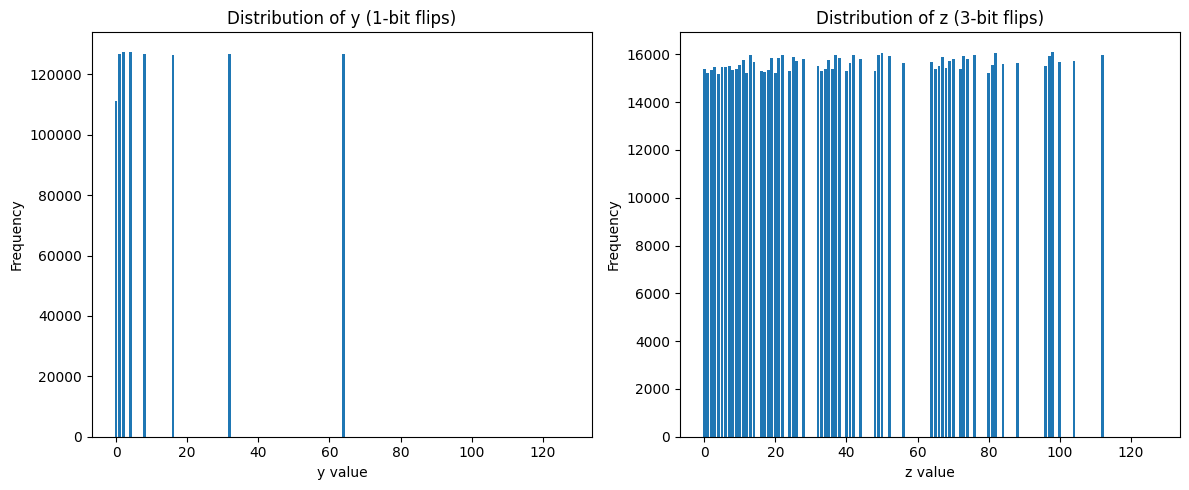

In [165]:
recived_masks = []
eavesdropper_masks = []
for _ in range(10**6):
  reciver = generate_mask(1)
  eavesdropper = generate_mask(3)
  recived_masks.append(reciver)
  eavesdropper_masks.append(eavesdropper)
# Plotting the results
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(recived_masks, bins=range(129), align='left', rwidth=0.8)
plt.title('Distribution of y (1-bit flips)')
plt.xlabel('y value')
plt.ylabel('Frequency')


plt.subplot(1, 2, 2)
plt.hist(eavesdropper_masks, bins=range(129), align='left', rwidth=0.8)
plt.title('Distribution of z (3-bit flips)')
plt.xlabel('z value')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


## wiretap channel

In [166]:
def wiretap_channel(message):
  reciver_mask = generate_mask(1)
  eavesdropper_mask = generate_mask(3)
  return message ^ reciver_mask, message ^ eavesdropper_mask

print(wiretap_channel(0b0))

(4, 64)


### Wiretap channel testing
plot different sample of the evesdropper recived message given the clean message

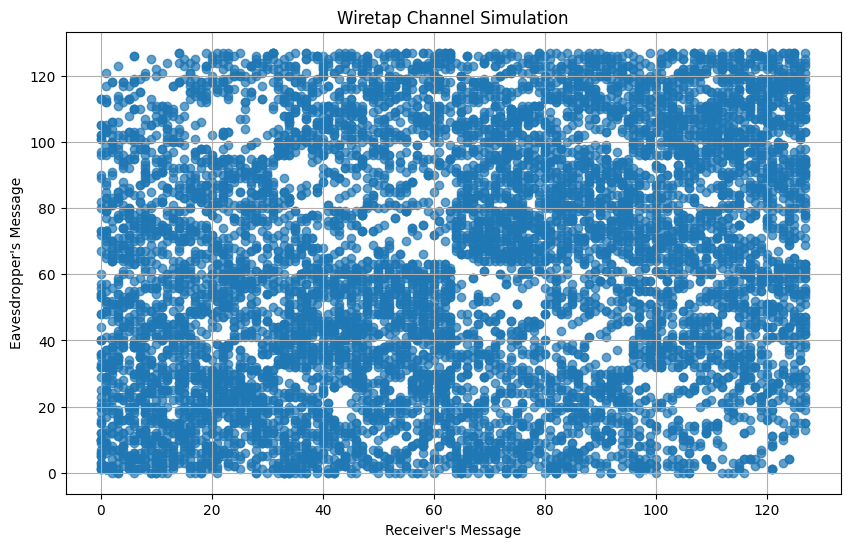

In [167]:
# Number of instances to simulate
num_instances = 10**4

# Store results
receiver_messages = []
eavesdropper_messages = []

# Iterate and simulate the wiretap channel
for _ in range(num_instances):
  message = random.randint(0, 127)  # Generate a random 7-bit message
  receiver_msg, eavesdropper_msg = wiretap_channel(message)
  receiver_messages.append(receiver_msg)
  eavesdropper_messages.append(eavesdropper_msg)

# Create the scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(receiver_messages, eavesdropper_messages, alpha=0.7)
plt.xlabel("Receiver's Message")
plt.ylabel("Eavesdropper's Message")
plt.title("Wiretap Channel Simulation")
plt.grid(True)
plt.show()


testing the probabilities of the channel

In [168]:
from collections import defaultdict
def create_combination_map(num_samples, message_size = 7):
  """Creates a map of wiretap channel output combinations and their frequencies.

  Args:
    num_samples: The number of random samples to generate.
    message: The message to be transmitted.

  Returns:
    A dictionary mapping (receiver_output, eavesdropper_output) tuples to their frequencies.
  """
  combination_map = defaultdict(int)
  for _ in range(num_samples):
    message = random.randint(0, 2**message_size)
    receiver_output, eavesdropper_output = wiretap_channel(message)
    combination_map[(receiver_output, eavesdropper_output)] += 1
  return combination_map

# Example usage:
num_samples = 10**6

combination_map = create_combination_map(num_samples)

In [204]:
def calculate_probabilities(combination_map):
  """Calculates probabilities for each key tuple and each single part of the key.

  Args:
    combination_map: The dictionary mapping (receiver_output, eavesdropper_output) tuples to their frequencies.

  Returns:
    A dictionary containing:
      - 'tuple_probabilities': A dictionary mapping key tuples to their probabilities.
      - 'receiver_probabilities': A dictionary mapping receiver outputs to their probabilities.
      - 'eavesdropper_probabilities': A dictionary mapping eavesdropper outputs to their probabilities.
  """
  total_samples = sum(combination_map.values())
  tuple_probabilities = {combination: frequency / total_samples for combination, frequency in combination_map.items()}
  receiver_probabilities = defaultdict(int)
  eavesdropper_probabilities = defaultdict(int)

  for combination, frequency in combination_map.items():
    receiver_output, eavesdropper_output = combination
    receiver_probabilities[receiver_output] += frequency
    eavesdropper_probabilities[eavesdropper_output] += frequency

  receiver_probabilities = {output: frequency / total_samples for output, frequency in receiver_probabilities.items()}
  eavesdropper_probabilities = {output: frequency / total_samples for output, frequency in eavesdropper_probabilities.items()}

  return {
      'tuple_probabilities': tuple_probabilities,
      'receiver_probabilities': receiver_probabilities,
      'eavesdropper_probabilities': eavesdropper_probabilities
  }

# Example usage:
# Assuming 'combination_map' is already created using 'create_combination_map'
probabilities = calculate_probabilities(combination_map)

In [203]:
def check_independence(probabilities, threshold = 1e-4):
  """Checks if the receiver's and eavesdropper's messages are independent.

  Args:
    probabilities: A dictionary containing tuple, receiver, and eavesdropper probabilities
                   (as returned by calculate_probabilities).

  Returns:
    True if the messages are independent, False otherwise.
  """
  tuple_probs = probabilities['tuple_probabilities']
  receiver_probs = probabilities['receiver_probabilities']
  eavesdropper_probs = probabilities['eavesdropper_probabilities']

  for receiver_msg, eavesdropper_msg in tuple_probs:
    # Calculate joint probability from individual probabilities (assuming independence)
    calculated_joint_prob = receiver_probs[receiver_msg] * eavesdropper_probs[eavesdropper_msg]

    # Compare with actual joint probability
    actual_joint_prob = tuple_probs[(receiver_msg, eavesdropper_msg)]

    # If significantly different, messages are not independent
    if abs(calculated_joint_prob - actual_joint_prob) > threshold:  # Using a small tolerance
      return False

  return True  # If all joint probabilities match, messages are likely independent

# Assuming 'probabilities' is already calculated
independence = check_independence(probabilities)
print("Receiver and Eavesdropper messages are independent:", independence)

Receiver and Eavesdropper messages are independent: True


# Task 2 & 3

2. implement the random binning encoder
3. implement the legitimate decoder

In [170]:
def hamming_distance(a, b):
  return bin(a ^ b).count('1')

def compose_message(first, second):
  return (first << 3) | second

def complement(message):
  return message^0b1111111

In [171]:
map = {0b000: 0b000, 0b001: 0b111,0b010: 0b011, 0b011: 0b100, 0b100: 0b101, 0b101: 0b010, 0b110: 0b110, 0b111: 0b001}
def encode(message):
    coded = compose_message(message, map[message])
    return [coded, complement(coded)]

def decode(message):
    min_distance = float('inf')  # Initialize with a large value
    min_key = None  # Initialize with None

    for key, value in map.items():
        possible = compose_message(key, value)
        distance = min(hamming_distance(message, possible),
                       hamming_distance(message, complement(possible)))

        if distance < min_distance:
            min_distance = distance
            min_key = key

    return min_key  # Return the key with the minimum distance

print("testing the encoding and decoding without the wiretap channel:")
for i in range(8):
  print(f"{i}, encoded {encode(i)}, decoded: [{decode(encode(i)[1])},{decode(encode(i)[1])}]")

testing the encoding and decoding without the wiretap channel:
0, encoded [0, 127], decoded: [0,0]
1, encoded [15, 112], decoded: [1,1]
2, encoded [19, 108], decoded: [2,2]
3, encoded [28, 99], decoded: [3,3]
4, encoded [37, 90], decoded: [4,4]
5, encoded [42, 85], decoded: [5,5]
6, encoded [54, 73], decoded: [6,6]
7, encoded [57, 70], decoded: [7,7]


simulate the wiretap channel returning a map containing, for each message u and for each message recived by the evasdropper the number of times that the pair (u,z) has been sampled

# Task 4

In [172]:
def wiretap_encoder_channel(message_range = 8, trials = 10):
    """given a message range it will iterate trials for each message and sample the
       evesdropper recived message mapping it into a dictionary of (u,z)->(#sample)
    """
    recived_map = defaultdict(lambda: defaultdict(int))
    for u in range(message_range):
      for _ in range(trials):
          encoded_message = encode(u)[random.randint(0,1)]
          _ , evesdropper = wiretap_channel(encoded_message)
          recived_map[u][evesdropper] += 1
    return recived_map

print(wiretap_encoder_channel())

defaultdict(<function wiretap_encoder_channel.<locals>.<lambda> at 0x7e0e9765cfe0>, {0: defaultdict(<class 'int'>, {98: 1, 44: 2, 49: 1, 81: 1, 109: 1, 6: 1, 38: 1, 8: 1, 88: 1}), 1: defaultdict(<class 'int'>, {18: 1, 72: 1, 82: 1, 55: 1, 54: 1, 30: 2, 108: 1, 14: 1, 122: 1}), 2: defaultdict(<class 'int'>, {3: 1, 91: 1, 114: 1, 77: 1, 4: 1, 13: 1, 93: 1, 37: 1, 17: 1, 8: 1}), 3: defaultdict(<class 'int'>, {2: 1, 123: 2, 91: 1, 112: 1, 9: 1, 74: 1, 103: 2, 58: 1}), 4: defaultdict(<class 'int'>, {105: 1, 31: 1, 71: 2, 91: 1, 122: 1, 32: 1, 12: 1, 116: 1, 80: 1}), 5: defaultdict(<class 'int'>, {40: 1, 110: 1, 101: 1, 119: 1, 0: 1, 31: 1, 53: 1, 77: 1, 81: 1, 24: 1}), 6: defaultdict(<class 'int'>, {15: 1, 3: 1, 11: 2, 108: 1, 101: 1, 23: 1, 116: 1, 44: 1, 56: 1}), 7: defaultdict(<class 'int'>, {111: 1, 30: 1, 2: 1, 45: 1, 95: 1, 125: 1, 27: 1, 108: 1, 81: 1, 8: 1})})


evaluating the probabilities

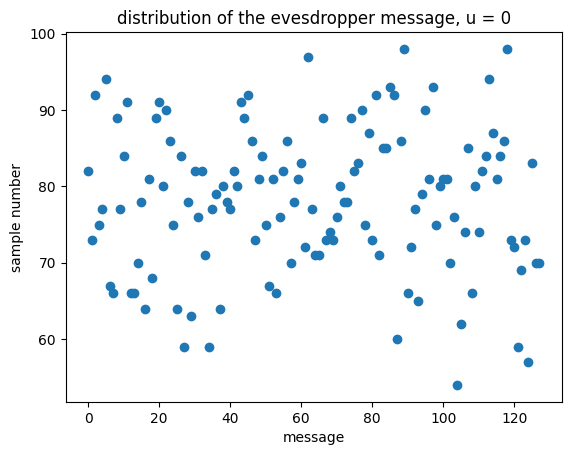

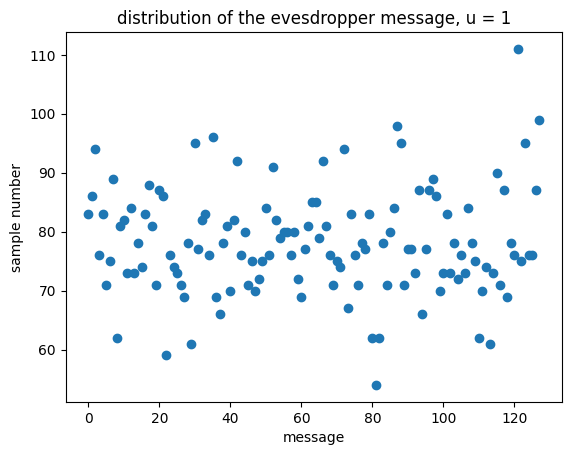

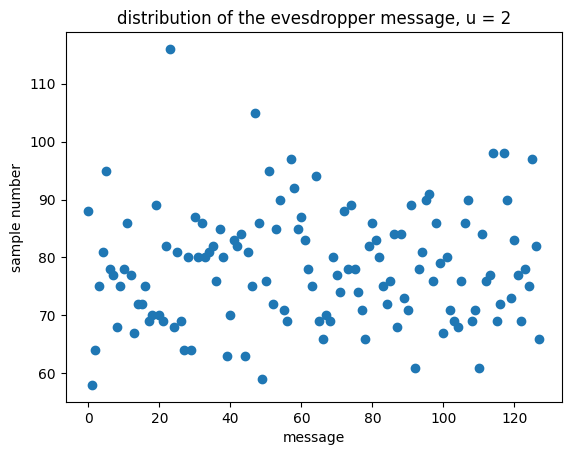

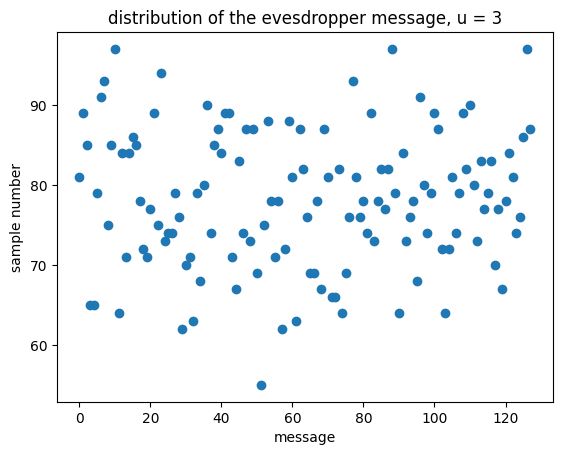

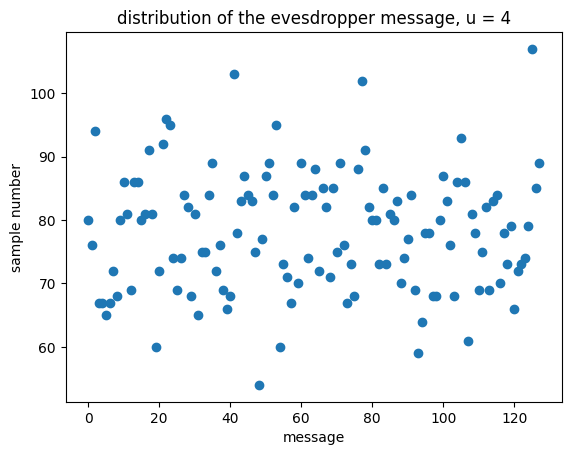

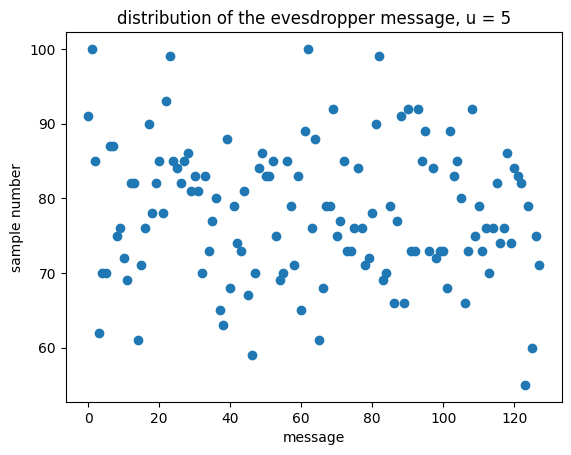

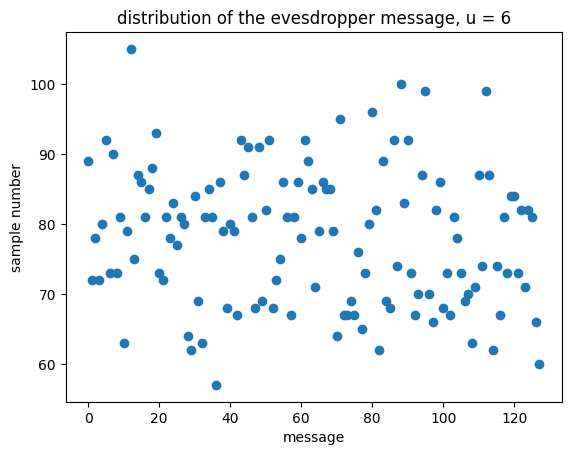

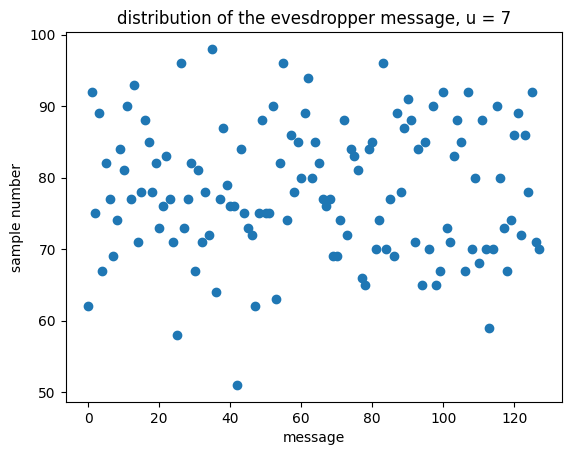

In [173]:
#Plotting different result from the wiretap channel, it seems that the probability to get the correct
#message is higher than the other one
test_channel = wiretap_encoder_channel(8, 10000)
for u in test_channel:
  scatter_plot_from_dict(test_channel[u], f"distribution of the evesdropper message, u = {u}", "message", "sample number")

evaluating mutual information

In [174]:
trials = 10**5
conditional_pmd_dict = conditional_pmd(wiretap_encoder_channel(trials = 10**5))
joint_pmd, marginal_pmd_z, marginal_pmd_u = channel_prob(conditional_pmd_dict)
print("mutual information: ", mutual_information(joint_pmd, marginal_pmd_z,marginal_pmd_u))

mutual information:  0.0009739724966280602


# Task 5

BSC

In [175]:
def BSC(message, epsilon, delta, message_lenghth = 7):
    m1 = message
    m2 = message
    for i in range(message_lenghth):
      if random.uniform(0.0, 1.0) < epsilon:
          m1 = m1 ^ (0b00000001 << i)

      if random.uniform(0.0, 1.0) < delta:
          m2 = m2 ^ (0b00000001 << i)
    return m1, m2

print(BSC(0b0, 0.5, 0.5))

(63, 22)


testing the bit error rate of the BSC, it should be equal to epsilon

In [176]:
def BSC_test_ber(test_size, message_size, epsilon):
  total_ber = 0  # Initialize to store the total BER across tests
  for i in range(test_size):
    message = random.randint(0, 2**message_size - 1)
    original_message_bin = bin(message)[2:].zfill(message_size)  # Original message as a binary string (pad with zeros if needed)
    received_message, _ = BSC(message, epsilon, 0, message_size)
    received_message_bin = bin(received_message)[2:].zfill(message_size)  # Received message as binary string
    total_ber += calculate_ber(original_message_bin, received_message_bin)  # Accumulate BER

  avg_ber = total_ber / test_size  # Average BER across all tests
  return avg_ber

correct_probabilities_ber = dict()  # Store BER results for different epsilon values
for i in range(10):
  epsilon = i * 0.1
  correct_probabilities_ber[epsilon] = BSC_test_ber(100, 20, epsilon)
print(correct_probabilities_ber)  # Display BER results

{0.0: 0.0, 0.1: 0.10349999999999994, 0.2: 0.20049999999999982, 0.30000000000000004: 0.3060000000000001, 0.4: 0.381, 0.5: 0.5259999999999999, 0.6000000000000001: 0.585, 0.7000000000000001: 0.6854999999999997, 0.8: 0.8049999999999997, 0.9: 0.8930000000000002}


# Task 6

channel definition: encoding and transmition

In [177]:
def BSC_channel(message, epsilon, delta):
  return BSC(encode(message)[random.randint(0, 1)],epsilon, delta)

### Reliability testing

In [178]:
##message_size = # bits per message
def test_reliability(test_size, message_size, epsilon):
  correct_test = 0
  for i in range(test_size):
    message = random.randint(0, 2**message_size - 1)
    recived_message = BSC_channel(message, epsilon, 0)[0]
    if decode(recived_message) == message:
      correct_test += 1
  return correct_test / test_size

correct_probabilities = dict()
for i in range(10):
  correct_probabilities[i*0.1] = test_reliability(10**5, 3, i*0.1)
print(correct_probabilities)

{0.0: 1.0, 0.1: 0.85217, 0.2: 0.57869, 0.30000000000000004: 0.33086, 0.4: 0.17757, 0.5: 0.12406, 0.6000000000000001: 0.17805, 0.7000000000000001: 0.33459, 0.8: 0.5774, 0.9: 0.84906}


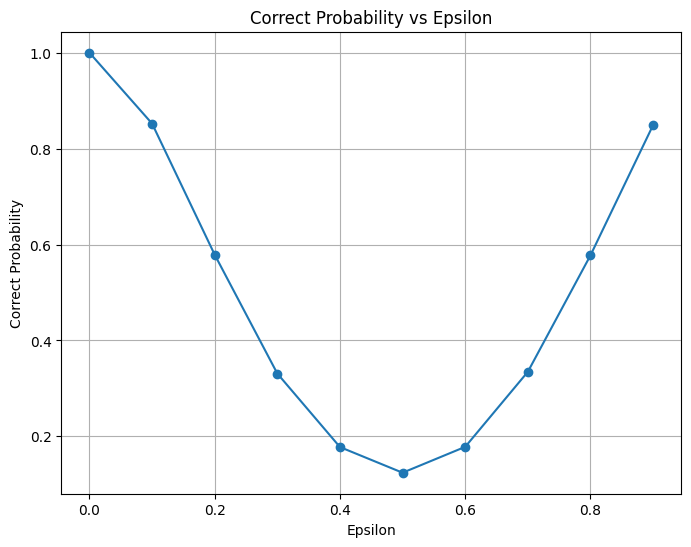

In [179]:
# Extract data for plotting
x_values = list(correct_probabilities.keys())
y_values = list(correct_probabilities.values())


# Create the plot
plt.figure(figsize=(8, 6))
plt.plot(x_values, y_values, marker='o')
plt.xlabel("Epsilon")
plt.ylabel("Correct Probability")
plt.title("Correct Probability vs Epsilon")
plt.grid(True)
plt.show()


### Mutual information and variation distance

In [180]:
def BSC_encoder_channel(epsilon, delta, message_range = 8, trials = 10):
    """simulate the channel for the evesdropper for each message in the message range
       over #trials for each message and return a dictionary of (u,z)->(#sample)
       -> only the delta parameter is used
    """
    recived_map = defaultdict(lambda: defaultdict(int))
    for u in range(message_range):
      for _ in range(trials):
          _ , evesdropper = BSC_channel(u, epsilon, delta)
          recived_map[u][evesdropper] += 1
    return recived_map

print(BSC_encoder_channel(0.5, 0.5))

defaultdict(<function BSC_encoder_channel.<locals>.<lambda> at 0x7e0e9c4ee700>, {0: defaultdict(<class 'int'>, {92: 1, 18: 1, 22: 1, 5: 1, 14: 1, 25: 1, 75: 1, 93: 1, 127: 1, 23: 1}), 1: defaultdict(<class 'int'>, {23: 1, 45: 1, 12: 1, 6: 1, 125: 1, 109: 1, 46: 1, 124: 1, 30: 1, 69: 1}), 2: defaultdict(<class 'int'>, {111: 1, 31: 1, 26: 1, 33: 1, 25: 1, 55: 1, 14: 1, 21: 1, 1: 1, 76: 1}), 3: defaultdict(<class 'int'>, {2: 1, 75: 1, 45: 1, 10: 1, 67: 1, 102: 1, 78: 1, 79: 1, 70: 1, 54: 1}), 4: defaultdict(<class 'int'>, {60: 1, 107: 1, 16: 1, 104: 1, 80: 1, 74: 1, 103: 1, 11: 1, 5: 1, 41: 1}), 5: defaultdict(<class 'int'>, {98: 1, 117: 1, 66: 1, 40: 1, 103: 1, 9: 1, 92: 1, 125: 1, 71: 1, 54: 1}), 6: defaultdict(<class 'int'>, {121: 1, 70: 2, 77: 1, 68: 1, 72: 1, 66: 1, 71: 1, 43: 1, 16: 1}), 7: defaultdict(<class 'int'>, {78: 3, 118: 1, 16: 1, 111: 1, 69: 1, 13: 1, 9: 1, 23: 1})})


The plot below show the frequency of message recived by the eveasdropper

mutual information:  0.008116311793952507


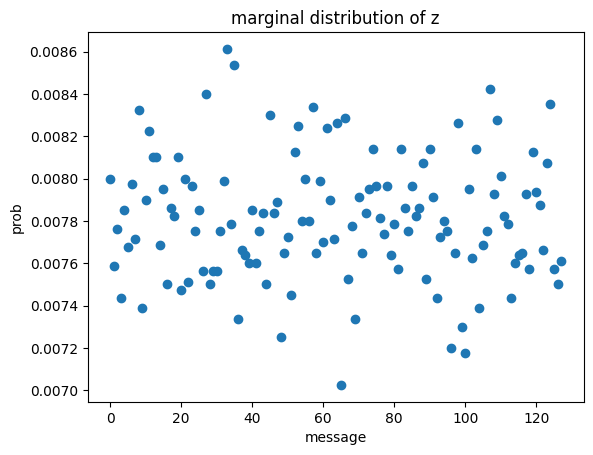

In [181]:
epsilon = 0.2
delta = 0.5
trials = 10**4
conditional_pmd_dict = conditional_pmd(BSC_encoder_channel(epsilon, delta, trials = trials))
joint_pmd, marginal_pmd_z, marginal_pmd_u = channel_prob(conditional_pmd_dict)
print("mutual information: ",mutual_information(joint_pmd, marginal_pmd_z,marginal_pmd_u))
scatter_plot_from_dict(marginal_pmd_z)

defining the channel used for the total variation distance, it creating a map containing both the information about z and u*

In [182]:
def BSC_full_encoder_channel(epsilon, delta, message_range = 8, trials = 10):
    """simulate the channel for the evesdropper (z) and the reciver (u')
       for each message in the message range
       over #trials for each message and return a dictionary of (u,z,u')->(#sample)
    """
    recived_map = defaultdict(lambda: defaultdict(lambda: defaultdict(int)))
    for u in range(message_range):
      for _ in range(trials):
          reciver , evesdropper = BSC_channel(u, epsilon, delta)
          reciver = decode(reciver)
          recived_map[u][evesdropper][reciver] += 1
    return recived_map

print(BSC_full_encoder_channel(0.5, 0.5))

defaultdict(<function BSC_full_encoder_channel.<locals>.<lambda> at 0x7e0e8b8093a0>, {0: defaultdict(<function BSC_full_encoder_channel.<locals>.<lambda>.<locals>.<lambda> at 0x7e0e8b7af7e0>, {111: defaultdict(<class 'int'>, {1: 1}), 49: defaultdict(<class 'int'>, {0: 1}), 87: defaultdict(<class 'int'>, {6: 1}), 45: defaultdict(<class 'int'>, {1: 1}), 55: defaultdict(<class 'int'>, {0: 1, 1: 1}), 115: defaultdict(<class 'int'>, {7: 1}), 94: defaultdict(<class 'int'>, {1: 1}), 73: defaultdict(<class 'int'>, {6: 1}), 112: defaultdict(<class 'int'>, {0: 1})}), 1: defaultdict(<function BSC_full_encoder_channel.<locals>.<lambda>.<locals>.<lambda> at 0x7e0e8b7afd80>, {72: defaultdict(<class 'int'>, {4: 1}), 103: defaultdict(<class 'int'>, {2: 1}), 96: defaultdict(<class 'int'>, {1: 2}), 114: defaultdict(<class 'int'>, {1: 1, 7: 1}), 1: defaultdict(<class 'int'>, {4: 1}), 46: defaultdict(<class 'int'>, {1: 1}), 29: defaultdict(<class 'int'>, {0: 1}), 9: defaultdict(<class 'int'>, {1: 1})}), 2

In [183]:
dictionary_ideal = BSC_full_encoder_channel(0, 0.5, trials = 10**3)
dictionary_real = BSC_full_encoder_channel(0.5, 0, trials = 10**3)
print("total var. distance: ",total_var_distance(dictionary_ideal, dictionary_real))

total var. distance:  0.9844999999999966


### testing different epsilon and delta for the BSC channel

Running simulation for epsilon=0.1, delta=0.5
Mutual Information: 0.008285438224463898
plot of the margina distribution of z


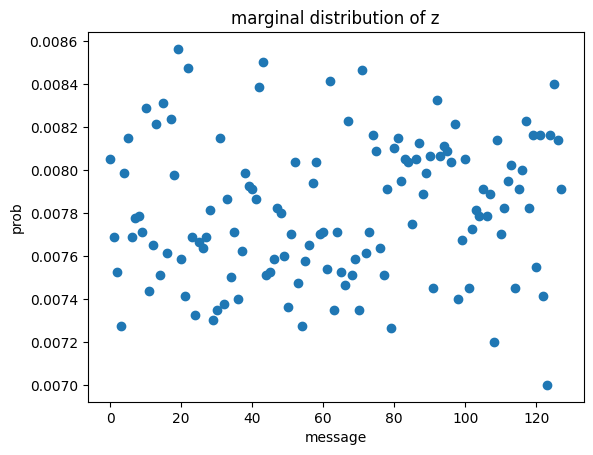

Total Variation Distance: 0.16566250000000396
Running simulation for epsilon=0.2, delta=0.4
Mutual Information: 0.029527371947895908
plot of the margina distribution of z


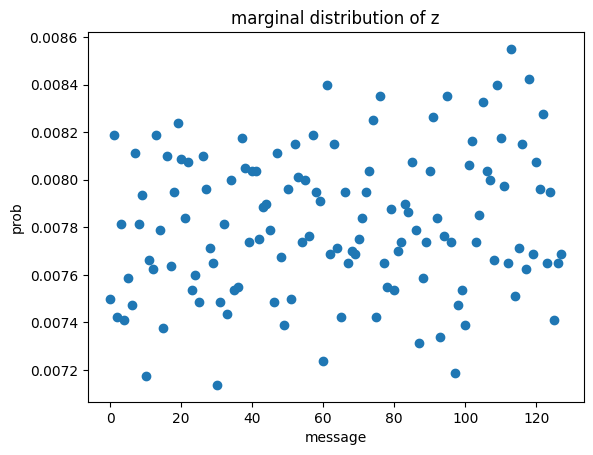

Total Variation Distance: 0.4253875000000148
Running simulation for epsilon=0.3, delta=0.3
Mutual Information: 0.28067154353397084
plot of the margina distribution of z


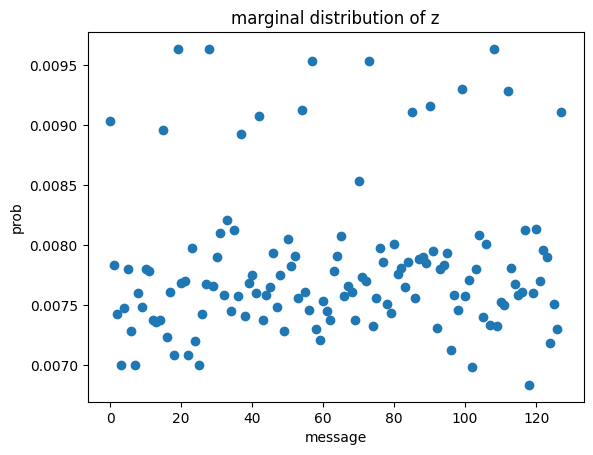

Total Variation Distance: 0.6771375000000169
Running simulation for epsilon=0.4, delta=0.2
Mutual Information: 1.0280403930699615
plot of the margina distribution of z


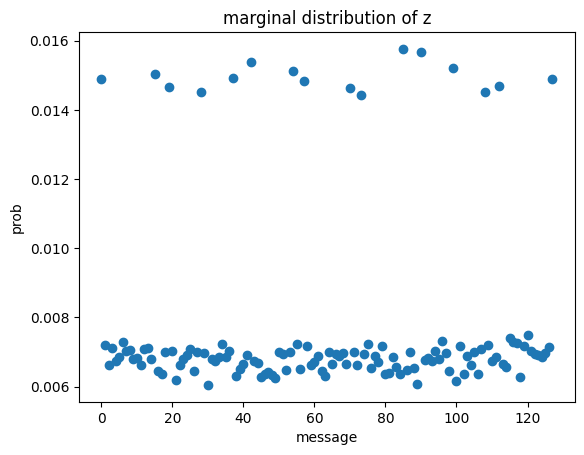

Total Variation Distance: 0.842399999999995
Running simulation for epsilon=0.5, delta=0.1
Mutual Information: 2.185787130014537
plot of the margina distribution of z


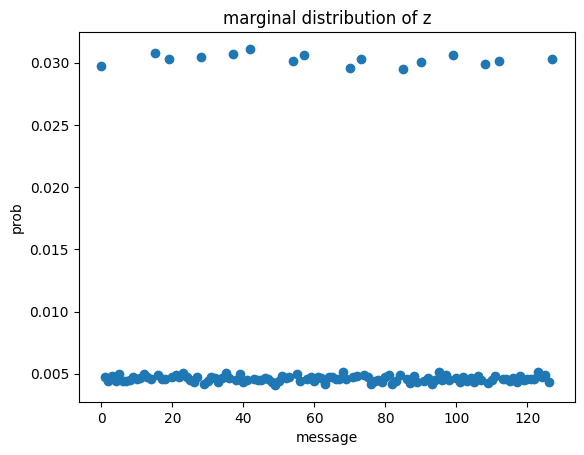

Total Variation Distance: 0.9177249999999942


In [184]:
epsilon_delta_pairs = [(0.1, 0.5), (0.2, 0.4), (0.3, 0.3), (0.4, 0.2), (0.5, 0.1)]  # Example pairs
trials = 10**4  # Number of trials per pair
for epsilon, delta in epsilon_delta_pairs:
    print(f"Running simulation for epsilon={epsilon}, delta={delta}")
    conditional_pmd_dict = conditional_pmd(BSC_encoder_channel(epsilon, delta, trials = trials))
    joint_pmd, marginal_pmd_z, marginal_pmd_u = channel_prob(conditional_pmd_dict)  # Adjust trials as needed
    mi = mutual_information(joint_pmd, marginal_pmd_z, marginal_pmd_u)
    print(f"Mutual Information: {mi}")
    print("plot of the margina distribution of z")
    scatter_plot_from_dict(marginal_pmd_z)
    dictionary_ideal = BSC_full_encoder_channel(0, 0.5, trials = trials)
    dictionary_real = BSC_full_encoder_channel(epsilon, delta, trials = trials)
    tv = total_var_distance(dictionary_ideal, dictionary_real)
    print(f"Total Variation Distance: {tv}")

# Task 7

implement the modulator + AWGN channel +
demodulator

In [185]:
#snr value: 16-40 good, >40 perfect; <16 bad
def AWGN_channel(signal, snr):
  """Adds Additive White Gaussian Noise (AWGN) to a signal.

  Args:
    signal: The input signal.

  Returns:
    The signal with added noise.
  """
    # Calculate noise power from SNR
  signal_power = np.abs(signal)**2
  noise_power = signal_power / (10**(snr / 10))  # Noise power from SNR
  # Generate AWGN
  noise = np.random.normal(0, np.sqrt(noise_power))
  # Add noise to the signal
  noisy_signal = signal + noise

  return noisy_signal
def PAM_module(message, M):
  """Modulates a message using Pulse Amplitude Modulation (PAM).

  Args:
    message: The input message (a sequence of integers).
    M: The number of modulation levels (constellation size).

  Returns:
    The modulated signal.
  """
  # Define the constellation points
  constellation = np.arange(-(M - 1), M, 2)

  # Map the message to constellation points
  modulated_signal = constellation[message]

  return modulated_signal

def PAM_demodulator(received_signal, M):
  """Demodulates a received signal using PAM.

  Args:
    received_signal: The received signal with noise.
    M: The number of modulation levels (constellation size).

  Returns:
    The demodulated message.
  """
  # Define the constellation points
  constellation = np.arange(-(M - 1), M, 2)

  # Find the nearest constellation point for each received sample
  demodulated_message = np.argmin(np.abs(received_signal - constellation))

  return demodulated_message

# Task 8

In [186]:
#simulate the entire awgn channel with the modulator and demodulator
def AWGN_PAM_channel(message, snr, message_range = 2**7):
    symbol = PAM_module(message, message_range)
    return PAM_demodulator(AWGN_channel(symbol, snr), message_range)
for i in range(8):
  print(f"sent {i}, recived {AWGN_PAM_channel(i, 40,8)}")

sent 0, recived 0
sent 1, recived 1
sent 2, recived 2
sent 3, recived 3
sent 4, recived 4
sent 5, recived 5
sent 6, recived 6
sent 7, recived 7


### BER evaluation for different snr

In [187]:
def test_reliability_ber(test_size, message_size, snr):
  total_ber = 0  # Initialize to store the total BER across tests
  for i in range(test_size):
    message = random.randint(0, 2**message_size - 1)
    original_message_bin = bin(message)[2:].zfill(message_size)  # Original message as a binary string (pad with zeros if needed)
    received_message = decode(AWGN_PAM_channel(encode(message)[random.randint(0,1)],snr))
    received_message_bin = bin(received_message)[2:].zfill(message_size)  # Received message as binary string
    total_ber += calculate_ber(original_message_bin, received_message_bin)  # Accumulate BER

  avg_ber = total_ber / test_size  # Average BER across all tests
  return avg_ber

correct_probabilities_ber = dict()  # Store BER results for different epsilon values
for i in range(12):
  snr = i * 4
  correct_probabilities_ber[snr] = test_reliability_ber(10, 3, snr)
print(correct_probabilities_ber)  # Display BER results

{0: 0.5666666666666667, 4: 0.33333333333333337, 8: 0.3, 12: 0.2666666666666667, 16: 0.2, 20: 0.2333333333333333, 24: 0.16666666666666666, 28: 0.06666666666666667, 32: 0.1, 36: 0.06666666666666667, 40: 0.0, 44: 0.0}


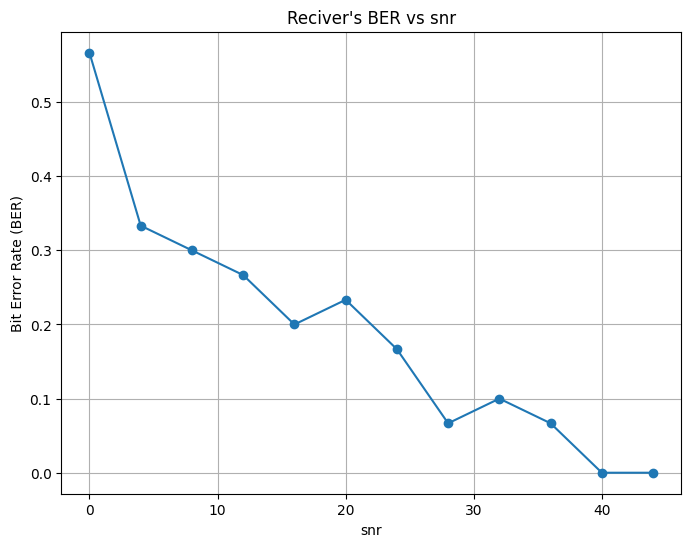

In [188]:
# Extract data for plotting
x_values = list(correct_probabilities_ber.keys())
y_values = list(correct_probabilities_ber.values())

# Create the plot
plt.figure(figsize=(8, 6))
plt.plot(x_values, y_values, marker='o')
plt.xlabel("snr")
plt.ylabel("Bit Error Rate (BER)")
plt.title("Reciver's BER vs snr")
plt.grid(True)
plt.show()

### Mutual information and total variation distance

In [189]:
def AWGN_encoder_channel(snr_evesdropper, message_range = 8, trials = 10):
    recived_map = defaultdict(lambda: defaultdict(int))
    for u in range(message_range):
      for _ in range(trials):
          message = encode(u)[random.randint(0, 1)]
          evesdropper = AWGN_PAM_channel(message, snr_evesdropper)
          recived_map[u][evesdropper] += 1
    return recived_map

print(BSC_encoder_channel(0.5, 0.5))

defaultdict(<function BSC_encoder_channel.<locals>.<lambda> at 0x7e0e9773c4a0>, {0: defaultdict(<class 'int'>, {11: 1, 30: 1, 75: 1, 9: 2, 82: 1, 98: 1, 102: 1, 127: 1, 101: 1}), 1: defaultdict(<class 'int'>, {61: 1, 109: 1, 74: 1, 94: 1, 9: 1, 43: 1, 83: 1, 62: 1, 100: 1, 21: 1}), 2: defaultdict(<class 'int'>, {7: 1, 89: 1, 56: 1, 64: 1, 86: 1, 102: 1, 85: 1, 62: 1, 54: 1, 33: 1}), 3: defaultdict(<class 'int'>, {46: 1, 36: 1, 11: 1, 33: 1, 73: 1, 106: 2, 31: 1, 109: 1, 115: 1}), 4: defaultdict(<class 'int'>, {111: 1, 8: 1, 123: 2, 103: 1, 91: 1, 122: 1, 54: 1, 0: 1, 48: 1}), 5: defaultdict(<class 'int'>, {64: 1, 99: 1, 118: 1, 83: 1, 25: 1, 8: 1, 86: 1, 107: 1, 72: 1, 126: 1}), 6: defaultdict(<class 'int'>, {23: 1, 119: 1, 82: 1, 68: 2, 40: 1, 77: 1, 30: 1, 71: 1, 43: 1}), 7: defaultdict(<class 'int'>, {7: 1, 27: 1, 56: 1, 57: 1, 83: 1, 39: 1, 13: 1, 108: 1, 55: 1, 26: 1})})


In [190]:
#different from
def AWGN_full_encoder_channel(snr_reciver, snr_evesdropper, message_range = 8, trials = 10):
    recived_map = defaultdict(lambda: defaultdict(lambda: defaultdict(int)))
    for u in range(message_range):
      for _ in range(trials):
          message = encode(u)[random.randint(0, 1)]
          reciver = AWGN_PAM_channel(message, snr_reciver)
          evesdropper = AWGN_PAM_channel(message, snr_evesdropper)
          reciver = decode(reciver)
          recived_map[u][evesdropper][reciver] += 1
    return recived_map

print(AWGN_full_encoder_channel(0.2, 0.5))

defaultdict(<function AWGN_full_encoder_channel.<locals>.<lambda> at 0x7e0e9773d620>, {0: defaultdict(<function AWGN_full_encoder_channel.<locals>.<lambda>.<locals>.<lambda> at 0x7e0e9773c860>, {np.int64(127): defaultdict(<class 'int'>, {7: 1, 0: 1}), np.int64(0): defaultdict(<class 'int'>, {2: 1, 1: 1, 0: 2}), np.int64(46): defaultdict(<class 'int'>, {2: 1}), np.int64(38): defaultdict(<class 'int'>, {0: 1}), np.int64(19): defaultdict(<class 'int'>, {0: 1}), np.int64(115): defaultdict(<class 'int'>, {0: 1})}), 1: defaultdict(<function AWGN_full_encoder_channel.<locals>.<lambda>.<locals>.<lambda> at 0x7e0e9773d760>, {np.int64(63): defaultdict(<class 'int'>, {3: 1}), np.int64(0): defaultdict(<class 'int'>, {1: 1, 0: 2}), np.int64(62): defaultdict(<class 'int'>, {0: 1}), np.int64(21): defaultdict(<class 'int'>, {0: 1}), np.int64(38): defaultdict(<class 'int'>, {3: 1}), np.int64(127): defaultdict(<class 'int'>, {0: 1, 5: 1, 7: 1})}), 2: defaultdict(<function AWGN_full_encoder_channel.<loca

Running simulation for snr_reciver=40, snr_evesdropper=4
Mutual Information: 0.6001089498953195
plot of the margina distribution of z


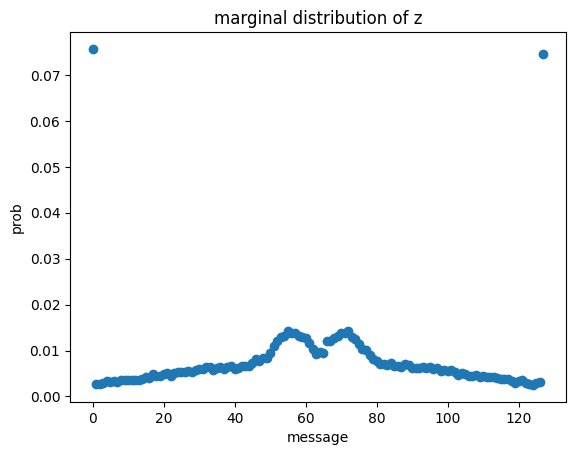

Total Variation Distance: 0.16432499999999925
--------------------------------
Running simulation for snr_reciver=32, snr_evesdropper=12
Mutual Information: 1.4059463265471455
plot of the margina distribution of z


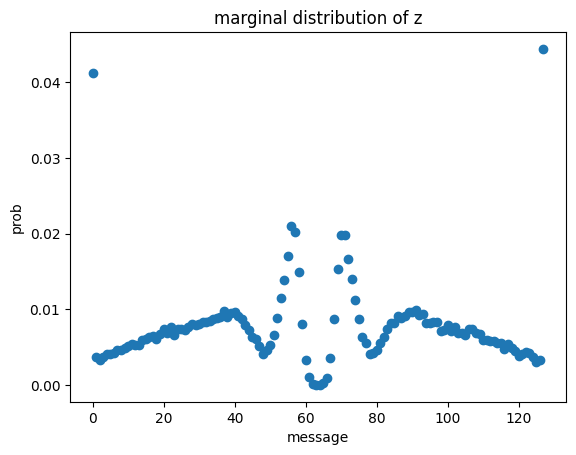

Total Variation Distance: 0.5206125000000025
--------------------------------
Running simulation for snr_reciver=24, snr_evesdropper=24
Mutual Information: 2.7018730109199898
plot of the margina distribution of z


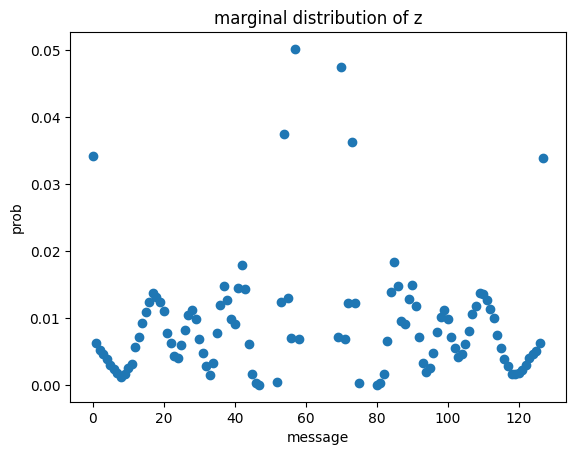

Total Variation Distance: 0.8014125000000007
--------------------------------
Running simulation for snr_reciver=12, snr_evesdropper=32
Mutual Information: 2.955297443460639
plot of the margina distribution of z


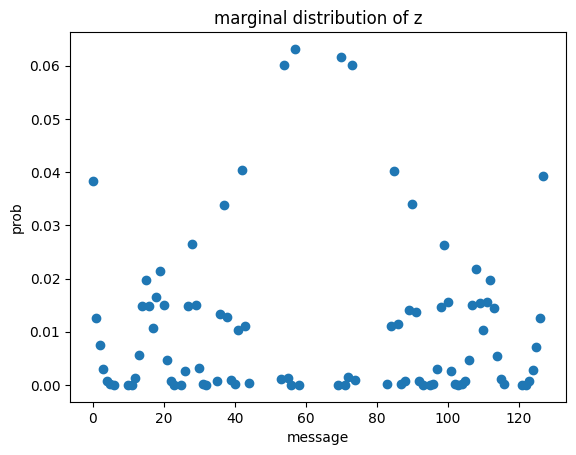

Total Variation Distance: 0.8924375000000004
--------------------------------
Running simulation for snr_reciver=4, snr_evesdropper=40
Mutual Information: 2.99986202116997
plot of the margina distribution of z


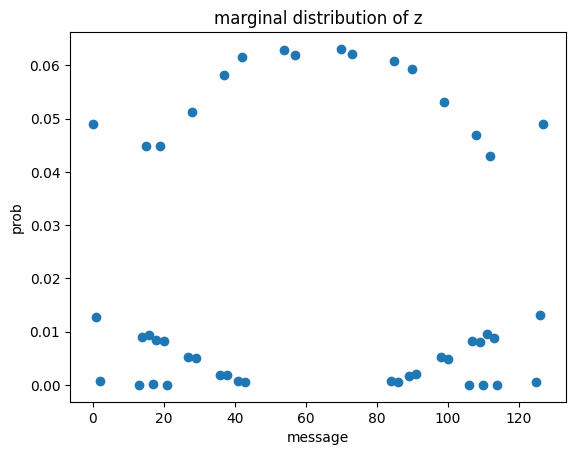

Total Variation Distance: 0.9098624999999997
--------------------------------


In [191]:
snr_pairs = [(40, 4), (32, 12), (24, 24), (12, 32), (4, 40)]  # Example pairs
trials = 10**4  # Number of trials per pair
for snr_reciver, snr_evesdropper in snr_pairs:
    print(f"Running simulation for snr_reciver={snr_reciver}, snr_evesdropper={snr_evesdropper}")
    conditional_pmd_dict = conditional_pmd(AWGN_encoder_channel(snr_evesdropper, trials = trials))
    joint_pmd, marginal_pmd_z, marginal_pmd_u = channel_prob(conditional_pmd_dict)  # Adjust trials as needed
    mi = mutual_information(joint_pmd, marginal_pmd_z, marginal_pmd_u)
    print(f"Mutual Information: {mi}")
    print("plot of the margina distribution of z")
    scatter_plot_from_dict(marginal_pmd_z)
    dictionary_ideal = AWGN_full_encoder_channel(1000, 0.0001, trials = trials)
    dictionary_real = AWGN_full_encoder_channel(snr_reciver, snr_evesdropper, trials = trials)
    tv = total_var_distance(dictionary_ideal, dictionary_real)
    print(f"Total Variation Distance: {tv}")
    print("--------------------------------")